# Chapter 11 — Novelty and Outlier Detection

**Book:** scikit-learn Cookbook, Third Edition — John Sukup (Packt Publishing, 2025)

This notebook follows the chapter sequence and demonstrates the core methods through executable examples. Numerical results appear immediately below the code, followed by a discussion of how to read them. The code examples are self-contained educational reproductions and extensions, not a word-for-word transcription of the text.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
np.set_printoptions(precision=3, suppress=True)
RANDOM_STATE=42

## 1. 1. Introduction to outlier and novelty detection

Outlier detection identifies unusual points within a dataset, while novelty detection learns a description of normal observations to evaluate new ones.

In [2]:
from sklearn.datasets import make_blobs
import numpy as np
regular,_=make_blobs(n_samples=250,centers=[[0,0]],cluster_std=.7,random_state=42)
unusual=np.array([[4,4],[-4,3],[3,-4]])
X=np.vstack([regular,unusual])
print('Normal-style observations:',len(regular))
print('Injected unusual observations:',len(unusual))

Normal-style observations: 250
Injected unusual observations: 3


**Interpretation.** The three injected points are visibly distant from the central cloud, making them convenient for comparing methods. Real anomalies are often much less obvious.

## 2. 2. Isolation Forest

Isolation Forest identifies anomalies by repeatedly partitioning the feature space. Points isolated by shorter paths tend to be more unusual.

In [3]:
from sklearn.ensemble import IsolationForest
iso=IsolationForest(contamination=.02,random_state=42).fit(X)
pred=iso.predict(X)
print('Anomalies detected:',sum(pred==-1))
print('Last three labels:',pred[-3:])
print('Last three anomaly scores:',np.round(iso.decision_function(X[-3:]),3))

Anomalies detected: 6
Last three labels: [-1 -1 -1]
Last three anomaly scores: [-0.201 -0.187 -0.211]


**Interpretation.** A prediction of -1 marks an outlier and 1 marks an inlier. The contamination parameter influences the number of flagged points and should reflect a plausible anomaly rate.

## 3. 3. Local Outlier Factor

Local Outlier Factor compares a point’s neighborhood density with densities around its neighbors. This helps locate observations that are unusual relative to their surroundings.

In [4]:
from sklearn.neighbors import LocalOutlierFactor
lof=LocalOutlierFactor(n_neighbors=20,contamination=.02)
lab=lof.fit_predict(X)
print('LOF anomalies:',sum(lab==-1))
print('Last three labels:',lab[-3:])
print('Last three negative outlier factors:',np.round(lof.negative_outlier_factor_[-3:],3))

LOF anomalies: 6
Last three labels: [-1 -1 -1]
Last three negative outlier factors: [-6.91  -6.356 -5.661]


**Interpretation.** More negative factor values indicate stronger local outlier evidence. Local methods can behave differently from global detectors on datasets with multiple densities.

## 4. 4. One-Class SVM novelty detection

One-Class SVM estimates a boundary around the normal training data. New observations outside that boundary can be flagged as novelties.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
oc=make_pipeline(StandardScaler(),OneClassSVM(kernel='rbf',nu=.03,gamma='scale')).fit(regular)
print('Predictions for unusual observations:',oc.predict(unusual))
print('Fraction accepted on training data:',round((oc.predict(regular)==1).mean(),3))

Predictions for unusual observations: [-1 -1 -1]
Fraction accepted on training data: 0.932


**Interpretation.** The novelty detector was fitted only on normal-style data, unlike a method fitted to a mixed dataset. This distinction matters when deciding which detection approach is appropriate.

## 5. 5. Evaluating anomaly predictions

When trusted anomaly labels are available, precision and recall can describe how many flagged points were true anomalies and how many anomalies were recovered.

In [6]:
from sklearn.metrics import precision_score, recall_score, f1_score
truth=np.r_[np.zeros(len(regular),dtype=int),np.ones(len(unusual),dtype=int)]
detected=(iso.predict(X)==-1).astype(int)
print('Precision:',round(precision_score(truth,detected,zero_division=0),3))
print('Recall:',round(recall_score(truth,detected,zero_division=0),3))
print('F1:',round(f1_score(truth,detected,zero_division=0),3))

Precision: 0.5
Recall: 1.0
F1: 0.667


**Interpretation.** An anomaly detector can have high recall while also raising false alarms. Most practical datasets do not have complete anomaly labels, which makes evaluation harder.

## 6. 6. Managing detected outliers

Detected outliers should not automatically be deleted. They might indicate measurement errors, uncommon but valid events, or the very cases the system needs to recognize.

In [7]:
flagged=np.where(iso.predict(X)==-1)[0]
print('First flagged indices:',flagged[:10])
print('Original data shape:',X.shape)
print('Shape if flagged rows were removed:',X[iso.predict(X)==1].shape)

First flagged indices: [ 75  87 136 250 251 252]
Original data shape: (253, 2)
Shape if flagged rows were removed: (247, 2)


**Interpretation.** The change in row count shows the practical effect of filtering. Any removal decision should be justified by data quality checks and the purpose of the analysis.

## 7. Outlier versus novelty detection

Outlier detection attempts to identify unusual points in training data; novelty detection learns ordinary patterns and checks new observations.

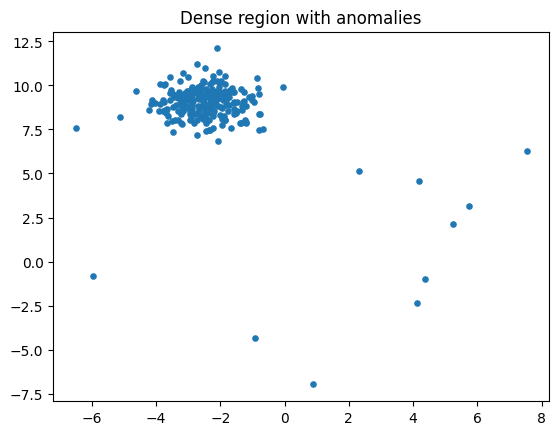

In [8]:
from sklearn.datasets import make_blobs
Xn,_=make_blobs(n_samples=240,centers=1,cluster_std=.8,random_state=42)
rng=np.random.default_rng(42);Xn=np.vstack([Xn,rng.uniform(-8,8,size=(12,2))])
plt.scatter(Xn[:,0],Xn[:,1],s=14);plt.title('Dense region with anomalies');plt.show()

**Interpretation.** The generated dataset has one dominant dense region and several scattered observations. Real anomalies may be much less obvious and depend on operational context.

## 8. Isolation Forest: anomaly predictions

Isolation Forest isolates unusual samples in randomized partition trees.

In [9]:
from sklearn.ensemble import IsolationForest
iso=IsolationForest(contamination=.05,random_state=42).fit(Xn)
flags=iso.predict(Xn)
print('Inliers:',sum(flags==1),'outliers:',sum(flags==-1))

Inliers: 239 outliers: 13


**Interpretation.** A -1 prediction is treated as an anomaly and +1 as normal. The contamination parameter helps set the decision threshold and should reflect the expected anomaly rate.

## 9. Isolation Forest anomaly scores

Decision scores rank how typical observations look relative to the learned model.

Lowest scores: [-0.21  -0.201 -0.188 -0.161 -0.147 -0.13  -0.127 -0.121]


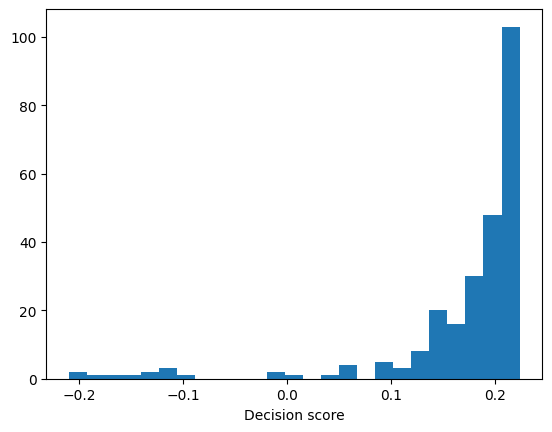

In [10]:
scores=iso.decision_function(Xn)
print('Lowest scores:',np.sort(scores)[:8].round(3));plt.hist(scores,bins=25);plt.xlabel('Decision score');plt.show()

**Interpretation.** Lower and negative decision scores identify more anomalous observations. Ranking by score can be more useful than treating all alerts as equally urgent.

## 10. Isolation Forest visualization

Plotting detected anomalies allows qualitative checks of spatial concentration and apparent false positives.

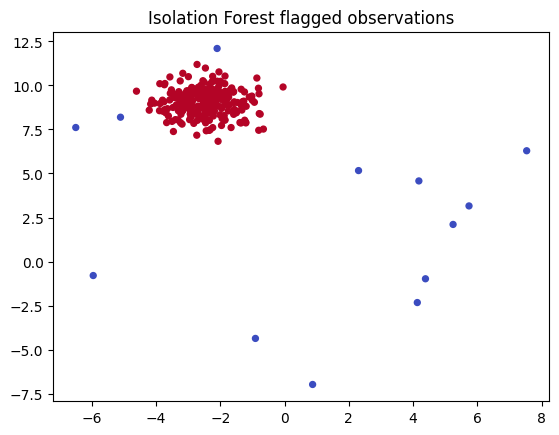

In [11]:
plt.scatter(Xn[:,0],Xn[:,1],c=flags,cmap='coolwarm',s=18);plt.title('Isolation Forest flagged observations');plt.show()

**Interpretation.** The marked samples often occur near the edges, but not every edge point is harmful. A visual inspection should be combined with knowledge of valid operating ranges.

## 11. Isolation Forest: effect of contamination

Contamination impacts the threshold used to flag unusual observations.

In [12]:
for c in [.01,.05,.10,.20]:
 m=IsolationForest(contamination=c,random_state=42).fit(Xn)
 print(c,int((m.predict(Xn)==-1).sum()))

0.01 3
0.05 13
0.1 26


0.2 51


**Interpretation.** More aggressive contamination levels typically produce more anomaly alerts. Choosing an unrealistically high value increases investigation cost and false alarms.

## 12. Local Outlier Factor

LOF compares local neighborhood density. An observation can be anomalous because it is sparse relative to its neighbors.

In [13]:
from sklearn.neighbors import LocalOutlierFactor
lof=LocalOutlierFactor(n_neighbors=20,contamination=.05)
lof_labels=lof.fit_predict(Xn)
print('Flagged:',sum(lof_labels==-1));print('Smallest LOF factors:',np.sort(lof.negative_outlier_factor_)[:5].round(3))

Flagged: 13
Smallest LOF factors: [-11.47   -9.457  -8.679  -7.806  -7.301]


**Interpretation.** LOF factors that are more negative correspond to locally unusual points. Neighborhood size changes what the model considers local.

## 13. LOF neighborhood sensitivity

Small neighborhoods focus on fine-scale density while large neighborhoods capture a broader density context.

In [14]:
for k in [5,10,20,40]:
 m=LocalOutlierFactor(n_neighbors=k,contamination=.05).fit(Xn)
 print(k,'score range:',np.round(np.quantile(m.negative_outlier_factor_,[0,.5,1]),2))

5 score range: [-9.43 -1.04 -0.9 ]
10 score range: [-10.71  -1.04  -0.94]
20 score range: [-11.47  -1.04  -0.96]
40 score range: [-13.15  -1.04  -0.95]


**Interpretation.** The LOF scoring distribution changes with n_neighbors. A small neighborhood can detect small local anomalies but may also react strongly to random density fluctuations.

## 14. One-Class SVM novelty detection

One-Class SVM fits a boundary around standard observations and can score new samples.

In [15]:
from sklearn.svm import OneClassSVM
normal=Xn[:240]
oc=make_pipeline(StandardScaler(),OneClassSVM(nu=.05,gamma='scale')).fit(normal)
print('Train anomalies:',int((oc.predict(normal)==-1).sum()))
print('Two new points:',oc.predict(np.array([[0,0],[15,15]])))

Train anomalies: 20
Two new points: [-1 -1]


**Interpretation.** An extreme new point is expected to be outside the learned distribution, although the result for any particular coordinate depends on training data and kernel parameters.

## 15. One-Class SVM parameter nu

The nu value constrains aspects of the learned boundary and controls tolerance for departures from common data.

In [16]:
for nu in [.01,.05,.1,.2]:
 m=make_pipeline(StandardScaler(),OneClassSVM(nu=nu,gamma='scale')).fit(normal)
 print(nu,int((m.predict(normal)==-1).sum()))

0.01 35
0.05 20
0.1 22
0.2 48


**Interpretation.** Higher nu often gives a tighter boundary with more training flags. It is not simply a guaranteed exact outlier percentage.

## 16. Comparing anomaly detection outputs

Different algorithms have different inductive biases; agreement of alerts can be used to prioritize manual review.

In [17]:
a=(iso.predict(Xn)==-1);b=(lof_labels==-1)
print('Both flag:',int((a&b).sum()),'Either flags:',int((a|b).sum()))

Both flag: 13 Either flags: 13


**Interpretation.** Agreement between methods can indicate conspicuous anomalies, but it does not establish ground truth. Different algorithms are sensitive to different structures.

## 17. Precision and recall on known anomalies

When synthetic or labeled anomalies are available, prediction quality can be measured using classification metrics.

In [18]:
from sklearn.metrics import precision_score,recall_score,f1_score
truth=np.array([0]*240+[1]*12)
pr=(iso.predict(Xn)==-1).astype(int)
print('Precision:',round(precision_score(truth,pr),3),'Recall:',round(recall_score(truth,pr),3),'F1:',round(f1_score(truth,pr),3))

Precision: 0.846 Recall: 0.917 F1: 0.88


**Interpretation.** Precision measures the fraction of alerts that are real anomalies; recall measures the fraction of real anomalies caught. Operational requirements decide which error is more costly.

## 18. Novelty detection with holdout data

A novelty detector should learn normal training observations without silently using test anomalies during fitting.

In [19]:
train=Xn[:200];test=np.vstack([Xn[200:240],Xn[240:]])
novel=make_pipeline(StandardScaler(),OneClassSVM(nu=.05,gamma='scale')).fit(train)
print('Holdout flags:',int((novel.predict(test)==-1).sum()),'of',len(test))

Holdout flags: 19 of 52


**Interpretation.** Holdout evaluation better resembles a production monitor. The anomaly mix in an artificial dataset should not be mistaken for real expected alert frequency.

## 19. Impact of scaling on anomaly detection

Feature scaling matters for algorithms based on distance or a kernel. It changes the geometry that defines abnormality.

In [20]:
Xwide=np.column_stack([Xn[:,0]*100,Xn[:,1]])
for scaled in [False,True]:
 m=make_pipeline(StandardScaler(),OneClassSVM(nu=.05)) if scaled else OneClassSVM(nu=.05)
 print('scaled',scaled,'flags',int((m.fit(Xwide).predict(Xwide)==-1).sum()))

scaled False flags 12
scaled True flags 11


**Interpretation.** Even if the number of flags is similar, the identity of flagged samples can change when scales differ. Comparing affected observations is more informative than comparing counts alone.

## 20. Inspecting and handling anomalies

An anomaly flag is a request for investigation, not an instruction to delete data. Review source measurements and legitimate extreme cases first.

In [21]:
frame=pd.DataFrame(Xn,columns=['feature_A','feature_B']);frame['is_outlier']=flags==-1
print(frame[frame.is_outlier].head(8).round(2).to_string(index=False))

 feature_A  feature_B  is_outlier
     -2.10      12.10        True
     -5.10       8.19        True
      4.38      -0.98        True
      5.74       3.16        True
     -6.49       7.61        True
      4.18       4.58        True
     -5.95      -0.79        True
      2.30       5.16        True


**Interpretation.** Reviewing flagged records supports data-quality decisions. Removing them automatically could discard rare but valid events that are valuable for a downstream model.